# Evaluating EDGE in finite samples

An observed log price is written as an unobserved fair log price plus bid-ask movement, while the indicator marks whether a bar contains a price change:

$$
p_t=\widetilde p_t+Z_t,
\qquad
\tau_t=
\begin{cases}
0,&h_t=l_t=c_{t-1},\\
1,&\text{otherwise}.
\end{cases}
$$

Here, $p_t$ is an observed log price; $\widetilde p_t$ is its unobserved fair component; $Z_t$ is bid-ask movement. $h_t,l_t,c_{t-1}$ are the high, low, and previous close log prices; $\tau_t$ is zero for a flat or forward-filled bar and one otherwise.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display

def compact_float_format(number_format=None):

    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value

def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch('[+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?', rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return '0'
    if ('.' in rendered or 'e' in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered

def compact_numeric_text(text):
    pattern = '(?<![0-9.eE])([+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])'
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)

def compact_table_latex(latex):
    return compact_numeric_text(latex)

def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + '</div>'

def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)
from pathlib import Path
import sys
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from IPython.display import Image
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
DATA_URL = 'https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1m/BTCUSDT-1m-2021-01.zip'
DATA_DIR = ROOT / 'data' / 'public' / 'binance'
DATA_PATH = ensure_dataset(ROOT, 'binance_btcusdt')
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
public_columns = ['Open time', 'Open', 'High', 'Low', 'Close', 'Volume', 'Close time', 'Quote volume', 'Trades', 'Buyer base volume', 'Buyer quote volume', 'Unused']
raw = pd.read_csv(DATA_PATH, compression='zip', header=None, names=public_columns, nrows=None)
raw['time'] = pd.to_datetime(raw['Open time'], unit='ms', utc=True).dt.tz_convert(None)
raw = raw.rename(columns={'Close': 'close', 'Volume': 'volume', 'Quote volume': 'quote_volume', 'Trades': 'trades'})
raw = raw.sort_values('time').drop_duplicates('time').reset_index(drop=True)
from RiskLabAI.features.microstructural_features import alpha_estimates, bekker_parkinson_volatility_estimates, beta_estimates, corwin_schultz_estimator, edge_estimator, gamma_estimates, sigma_estimates
numeric_columns = ['Open', 'High', 'Low', 'close', 'volume', 'quote_volume', 'trades']
raw[numeric_columns] = raw[numeric_columns].apply(pd.to_numeric)
minute = raw.rename(columns={'Open': 'open', 'High': 'high', 'Low': 'low'}).set_index('time')[['open', 'high', 'low', 'close', 'volume', 'quote_volume', 'trades']]

def make_bars(rule):
    return minute.resample(rule).agg({'open': 'first', 'high': 'max', 'low': 'min', 'close': 'last', 'volume': 'sum', 'quote_volume': 'sum', 'trades': 'sum'}).dropna()
bars_15 = make_bars('15min')
FIGURES = ROOT / 'outputs' / 'figures' / '11_market_microstructure'
TABLES = ROOT / 'outputs' / 'tables' / '11_market_microstructure'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
palette = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151'}
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': palette['background'], 'axes.facecolor': palette['axes'], 'axes.edgecolor': palette['text'], 'axes.labelcolor': palette['text'], 'axes.titlecolor': palette['text'], 'xtick.color': palette['text'], 'ytick.color': palette['text'], 'text.color': palette['text'], 'grid.color': palette['grid'], 'grid.linestyle': ':', 'legend.facecolor': palette['axes'], 'legend.edgecolor': palette['grid'], 'savefig.facecolor': palette['background']})

def save_table(frame, stem, caption, label, float_format='%.6f', fit=True):
    frame.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position='H'))
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\begin{adjustbox}{max width=\\textwidth}\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}\\end{adjustbox}', 1)
    else:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{tabular}', 1)
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': '#111827', 'axes.facecolor': '#111827', 'axes.edgecolor': '#94A3B8', 'axes.labelcolor': '#E5E7EB', 'axes.titlecolor': '#E5E7EB', 'axes.titleweight': 'bold', 'xtick.color': '#94A3B8', 'ytick.color': '#94A3B8', 'text.color': '#E5E7EB', 'grid.color': '#374151', 'grid.linestyle': ':', 'grid.linewidth': 0.8, 'legend.facecolor': '#111827', 'legend.edgecolor': '#374151', 'legend.framealpha': 0.96, 'savefig.facecolor': '#111827', 'savefig.transparent': False, 'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == '3.2.0'


## Efficient Combination of Two Measurements

EDGE gives more weight to the squared-spread measurement with lower variance, then converts the combined squared estimate to a spread:

$$
\widehat S_{\mathrm{EDGE}}^{2}
=\frac{v_2e_1+v_1e_2}{v_1+v_2},
\qquad
\widehat S_{\mathrm{mag}}=\sqrt{\left|\widehat S_{\mathrm{EDGE}}^{2}\right|},
\qquad
\widehat S_{0}=\sqrt{\max\!\left\{0,\widehat S_{\mathrm{EDGE}}^{2}\right\}}.
$$

Here, $e_1,e_2$ are the sample means of two squared-spread measurements; $v_1,v_2$ are their sample variances. $\widehat S_{\mathrm{EDGE}}^{2}$ is the combined squared estimate; $\widehat S_{\mathrm{mag}}$ is the public library's magnitude form; $\widehat S_0$ floors a negative squared estimate at zero.

,Estimator,Windows,"Mean, basis points","Median, basis points","Standard deviation, basis points","10th percentile, basis points","90th percentile, basis points",Nonpositive share
0,EDGE magnitude,721,2.622996,2.295395,1.510473,1.015106,4.537415,0
1,EDGE zero floor,721,1.267980,0,1.979942,0,4.254832,0.600555
2,EDGE signed,721,-0.087036,-1.353407,3.027145,-3.325182,4.254832,0.600555
3,Corwin-Schultz average,721,28.803430,26.686536,10.280281,19.564042,40.242205,0


,Window bars,Windows,"EDGE median, basis points","EDGE zero-floor median, basis points","Corwin-Schultz median, basis points",Negative squared EDGE share
0,24,493,2.614863,0,25.243611,0.565923
1,48,245,2.400532,0,25.842400,0.542857
2,96,121,2.284986,0,26.864645,0.611570
3,192,59,2.317561,0,27.451039,0.610169
4,384,28,2.017060,0,28.318349,0.535714


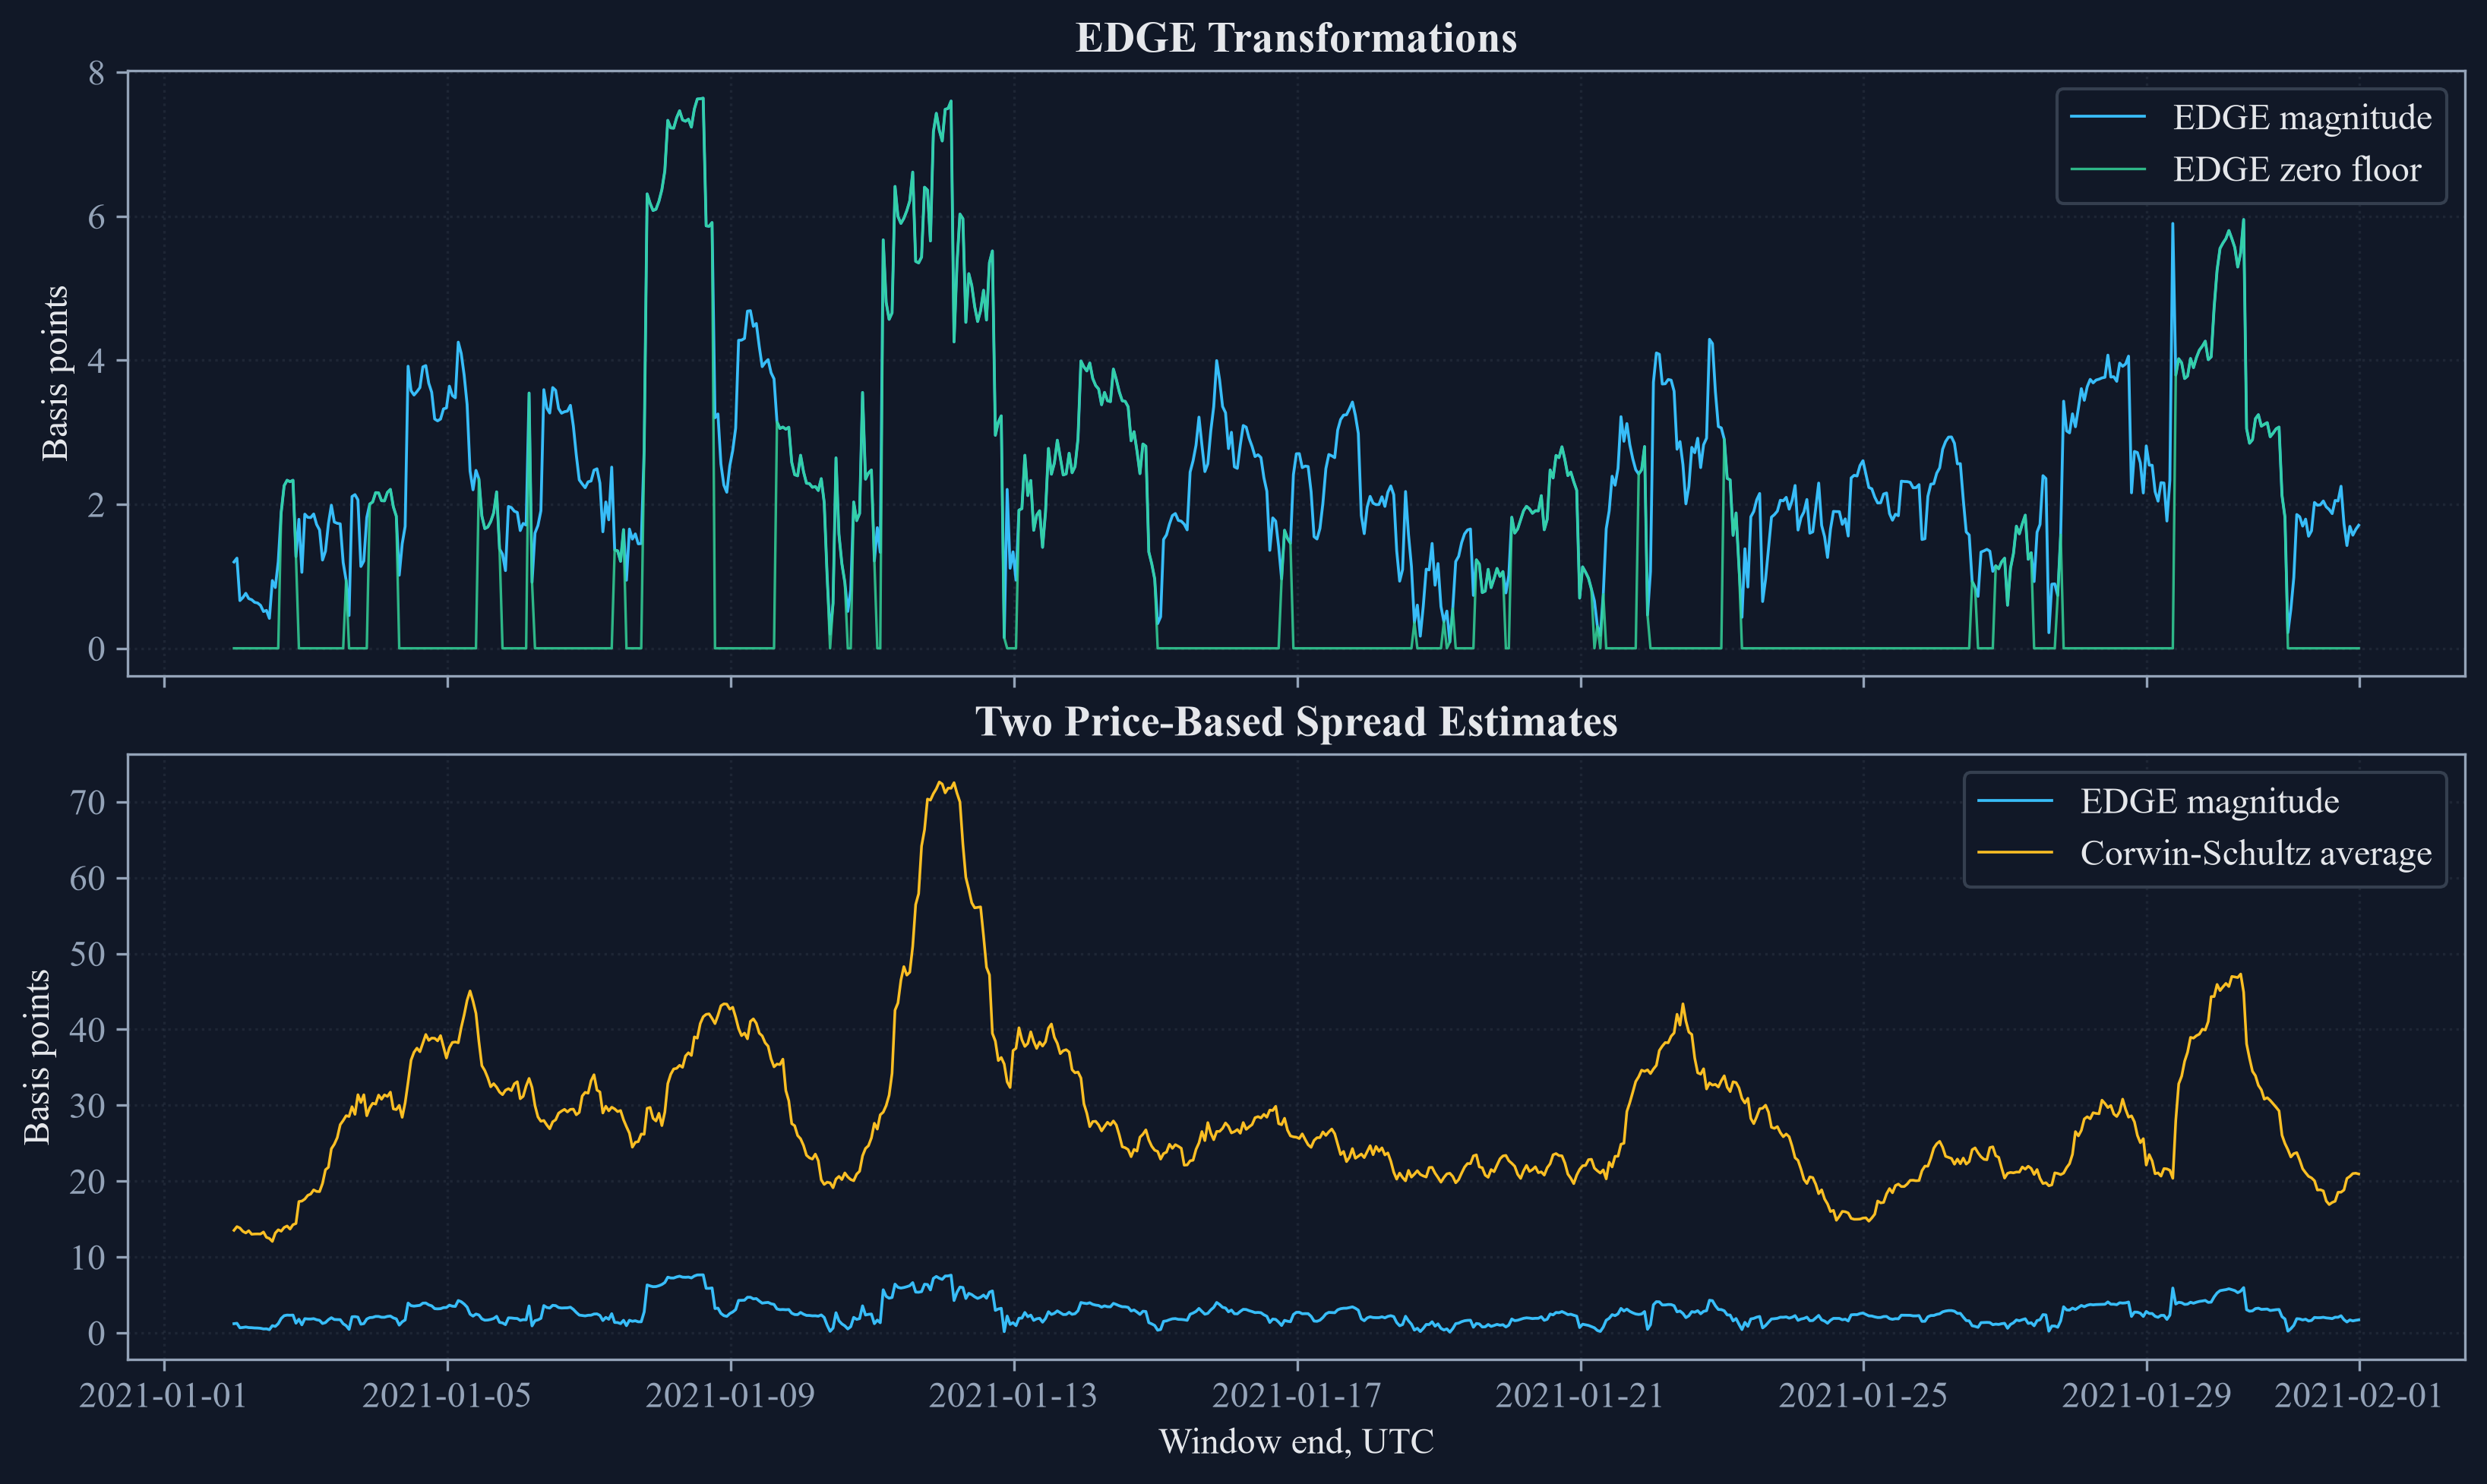

In [2]:
rolling_window = 96
rolling_step = 4
public_rows = []
for endpoint in range(rolling_window - 1, len(bars_15), rolling_step):
    sample = bars_15.iloc[endpoint - rolling_window + 1 : endpoint + 1]
    edge_magnitude = edge_estimator(sample["open"], sample["high"], sample["low"], sample["close"])
    edge_signed = edge_estimator(sample["open"], sample["high"], sample["low"], sample["close"], sign=True)
    cs_path = corwin_schultz_estimator(sample["high"], sample["low"], 1)
    public_rows.append({"Time": sample.index[-1], "EDGE magnitude": edge_magnitude, "EDGE zero floor": max(edge_signed, 0.0), "EDGE signed": edge_signed, "Corwin-Schultz average": cs_path.mean()})
public_estimates = pd.DataFrame(public_rows).set_index("Time")

edge_public_summary = pd.DataFrame([
    {"Estimator": name, "Windows": series.notna().sum(), "Mean, basis points": 10000 * series.mean(), "Median, basis points": 10000 * series.median(), "Standard deviation, basis points": 10000 * series.std(), "10th percentile, basis points": 10000 * series.quantile(0.10), "90th percentile, basis points": 10000 * series.quantile(0.90), "Nonpositive share": (series <= 0).mean()}
    for name, series in public_estimates.items()
])
save_table(edge_public_summary, "edge_public_summary", "Public rolling spread estimates from 96 fifteen-minute bars.", "tab:chapter10-edge-public-summary", fit=True)
display(edge_public_summary.round(6))

public_sensitivity_rows = []
for current_window in [24, 48, 96, 192, 384]:
    edge_values = []
    cs_values = []
    signed_values = []
    current_step = max(4, current_window // 4)
    for endpoint in range(current_window - 1, len(bars_15), current_step):
        sample = bars_15.iloc[endpoint - current_window + 1 : endpoint + 1]
        edge_values.append(edge_estimator(sample["open"], sample["high"], sample["low"], sample["close"]))
        signed_values.append(edge_estimator(sample["open"], sample["high"], sample["low"], sample["close"], sign=True))
        cs_values.append(corwin_schultz_estimator(sample["high"], sample["low"], 1).mean())
    edge_values = pd.Series(edge_values, dtype=float)
    signed_values = pd.Series(signed_values, dtype=float)
    cs_values = pd.Series(cs_values, dtype=float)
    public_sensitivity_rows.append({"Window bars": current_window, "Windows": edge_values.notna().sum(), "EDGE median, basis points": 10000 * edge_values.median(), "EDGE zero-floor median, basis points": 10000 * signed_values.clip(lower=0).median(), "Corwin-Schultz median, basis points": 10000 * cs_values.median(), "Negative squared EDGE share": (signed_values < 0).mean()})
edge_window_sensitivity = pd.DataFrame(public_sensitivity_rows)
save_table(edge_window_sensitivity, "edge_window_sensitivity", "Public spread estimates across rolling window lengths.", "tab:chapter10-edge-window-sensitivity", fit=True)
display(edge_window_sensitivity.round(6))

figure, axes = plt.subplots(2, 1, figsize=(10.8, 6.4), sharex=True, constrained_layout=True)
axes[0].plot(public_estimates.index, 10000 * public_estimates["EDGE magnitude"], color=palette["cyan"], linewidth=0.9, label="EDGE magnitude")
axes[0].plot(public_estimates.index, 10000 * public_estimates["EDGE zero floor"], color=palette["green"], linewidth=0.8, alpha=0.85, label="EDGE zero floor")
axes[0].set_title("EDGE Transformations")
axes[0].set_ylabel("Basis points")
axes[0].legend()
axes[1].plot(public_estimates.index, 10000 * public_estimates["EDGE magnitude"], color=palette["cyan"], linewidth=0.9, label="EDGE magnitude")
axes[1].plot(public_estimates.index, 10000 * public_estimates["Corwin-Schultz average"], color=palette["amber"], linewidth=0.85, label="Corwin-Schultz average")
axes[1].set_title("Two Price-Based Spread Estimates")
axes[1].set_xlabel("Window end, UTC")
axes[1].set_ylabel("Basis points")
axes[1].legend()
for axis in axes:
    axis.grid(alpha=0.35)
figure.savefig(FIGURES / "public_edge_comparison.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "public_edge_comparison.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "public_edge_comparison.png")))
plt.close(figure)

## Known-Truth Finite-Sample Comparison

Bias measures average signed error, while root mean squared error measures the typical error size and gives extra weight to large errors:

$$
\operatorname{Bias}(\widehat S)
=\frac{1}{B}\sum_{b=1}^{B}(\widehat S_b-S_0),
\qquad
\operatorname{RMSE}(\widehat S)
=\sqrt{\frac{1}{B}\sum_{b=1}^{B}(\widehat S_b-S_0)^2}.
$$

Here, $\widehat S_b$ is the spread estimate in repetition $b$; $S_0$ is the known spread used to generate prices. $B$ is the number of repetitions; $\operatorname{Bias}$ is signed average error; $\operatorname{RMSE}$ is the square root of average squared error.

,Item,Value
0,Bars per repetition,42
1,Trade opportunities per bar,60
2,Bar volatility,0.0200
3,True spreads,"0.0025, 0.0050, 0.0100, 0.0200"
4,Expected trades per bar,"3, 12, 60"
5,Repetitions per setting,120
6,Total generated price samples,1440


,"True spread, basis points",Expected trades per bar,Estimator,Valid repetitions,"Mean estimate, basis points","Bias, basis points","RMSE, basis points","Standard deviation, basis points"
18,100,3,Corwin-Schultz,120,13.452727,-86.547273,86.734110,5.713797
19,100,3,EDGE magnitude,120,102.128134,2.128134,37.183731,37.278433
20,100,3,EDGE zero floor,120,93.617516,-6.382484,48.609930,48.391149
21,100,12,Corwin-Schultz,120,66.370960,-33.629040,36.350307,13.857589
22,100,12,EDGE magnitude,120,94.400219,-5.599781,30.558300,30.166799
23,100,12,EDGE zero floor,120,91.369340,-8.630660,36.463690,35.576109
24,100,60,Corwin-Schultz,120,116.265623,16.265623,23.996446,17.716505
25,100,60,EDGE magnitude,120,97.115858,-2.884142,22.882277,22.794964
26,100,60,EDGE zero floor,120,96.867383,-3.132617,23.863585,23.756271


,Estimator,"Mean absolute bias, basis points","Mean RMSE, basis points",Lowest RMSE settings,Compared settings
1,EDGE magnitude,12.669420,32.048898,8,12
2,EDGE zero floor,5.815015,33.721844,0,12
0,Corwin-Schultz,46.652532,50.634521,4,12


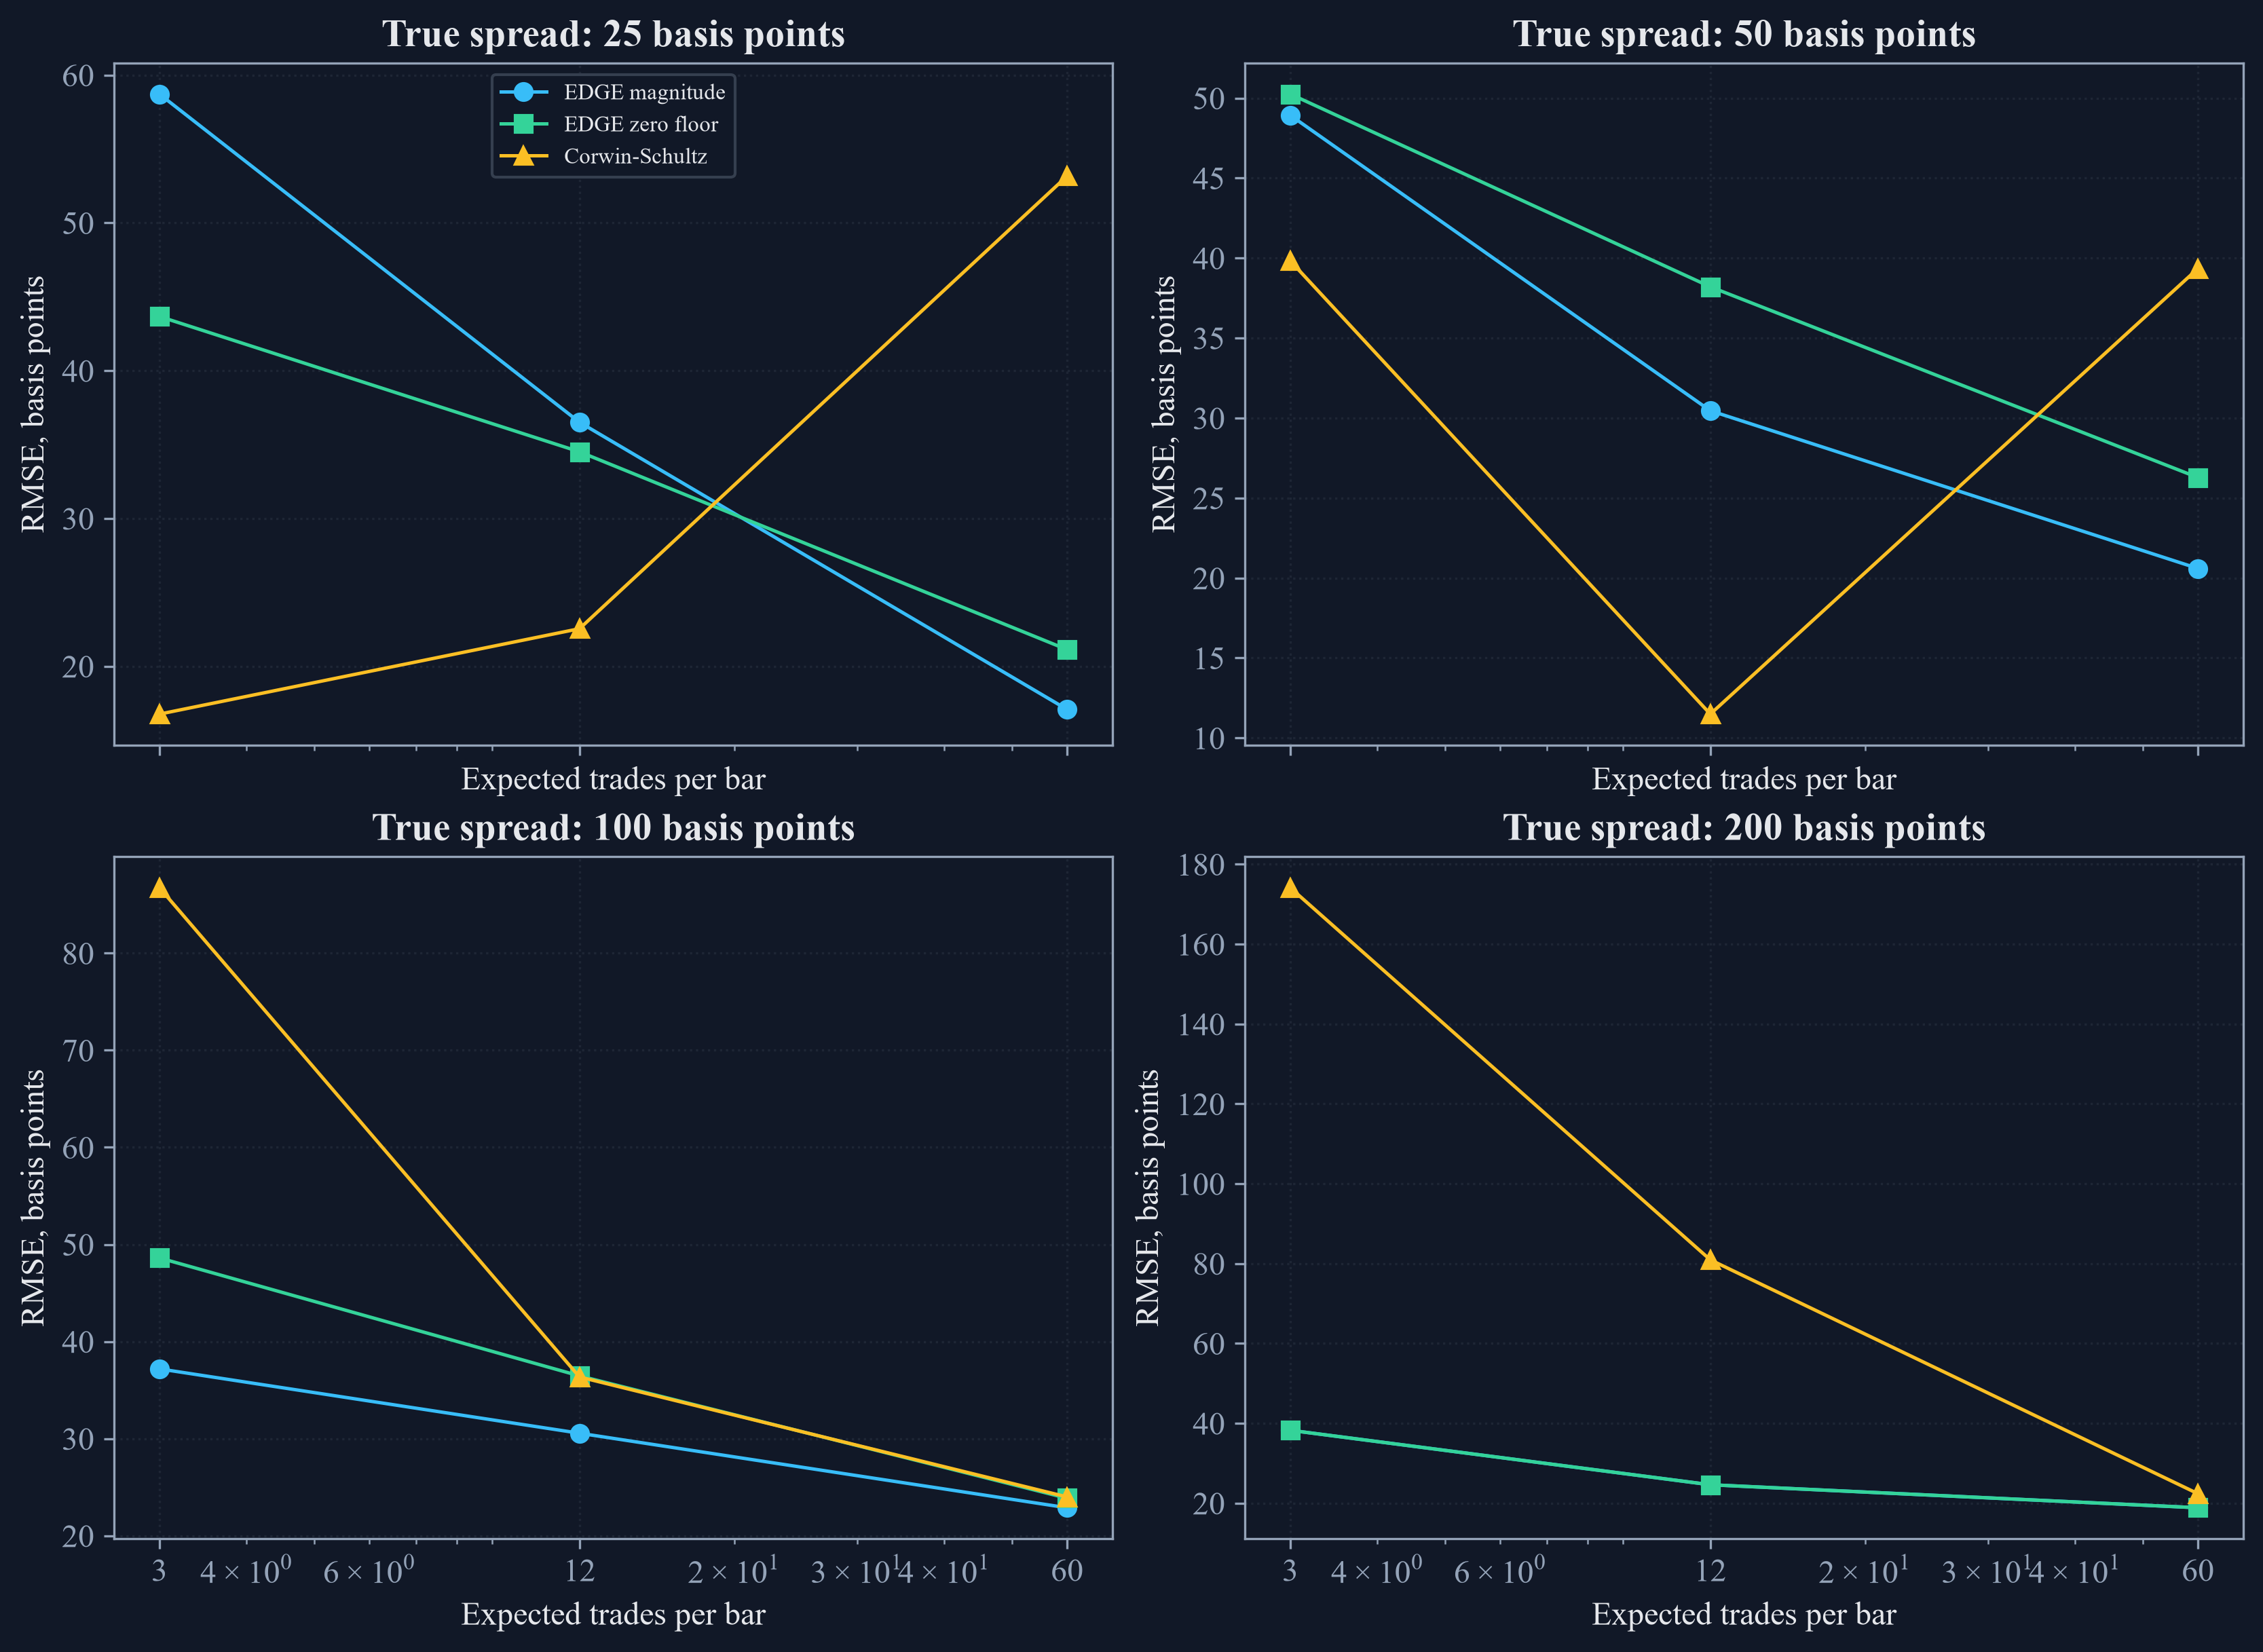

In [3]:
def simulate_ohlc(seed, true_spread, expected_trades, bars=42, opportunities=60, bar_volatility=0.02):
    rng = np.random.default_rng(seed)
    latent_price = 100.0
    previous_close = 100.0
    records = []
    observation_probability = min(expected_trades / opportunities, 1.0)
    step_volatility = bar_volatility / np.sqrt(opportunities)
    for _ in range(bars):
        increments = -0.5 * step_volatility**2 + step_volatility * rng.standard_normal(opportunities)
        latent_path = latent_price * np.exp(np.cumsum(increments))
        observed = rng.random(opportunities) < observation_probability
        if observed.any():
            sides = rng.choice(np.array([-1.0, 1.0]), size=int(observed.sum()))
            transactions = latent_path[observed] * (1 + sides * true_spread / 2)
            bar_open = float(transactions[0])
            bar_high = float(transactions.max())
            bar_low = float(transactions.min())
            bar_close = float(transactions[-1])
        else:
            bar_open = previous_close
            bar_high = previous_close
            bar_low = previous_close
            bar_close = previous_close
        records.append((bar_open, bar_high, bar_low, bar_close))
        latent_price = float(latent_path[-1])
        previous_close = bar_close
    return pd.DataFrame(records, columns=["open", "high", "low", "close"])

def estimate_spreads(sample):
    edge_magnitude = edge_estimator(sample["open"], sample["high"], sample["low"], sample["close"])
    edge_signed = edge_estimator(sample["open"], sample["high"], sample["low"], sample["close"], sign=True)
    cs_value = corwin_schultz_estimator(sample["high"], sample["low"], 1).mean()
    return {"EDGE magnitude": edge_magnitude, "EDGE zero floor": max(edge_signed, 0.0), "Corwin-Schultz": cs_value}

true_spreads = [0.0025, 0.0050, 0.0100, 0.0200]
expected_trade_counts = [3, 12, 60]
repetitions = 120
seed_sequence = np.random.SeedSequence(20260926)
child_seeds = iter(seed_sequence.spawn(len(true_spreads) * len(expected_trade_counts) * repetitions))
simulation_rows = []
for true_spread in true_spreads:
    for expected_trades in expected_trade_counts:
        for repetition in range(repetitions):
            sample = simulate_ohlc(next(child_seeds), true_spread, expected_trades)
            estimates = estimate_spreads(sample)
            for method, estimate in estimates.items():
                simulation_rows.append({"True spread": true_spread, "Expected trades per bar": expected_trades, "Repetition": repetition, "Estimator": method, "Estimate": estimate})
simulation_results = pd.DataFrame(simulation_rows).dropna()

grouped_rows = []
for (true_spread, expected_trades, method), group in simulation_results.groupby(["True spread", "Expected trades per bar", "Estimator"], sort=True):
    errors = group["Estimate"] - true_spread
    grouped_rows.append({"True spread": true_spread, "Expected trades per bar": expected_trades, "Estimator": method, "Valid repetitions": len(group), "Mean estimate": group["Estimate"].mean(), "Bias": errors.mean(), "RMSE": np.sqrt(np.mean(errors**2)), "Standard deviation": group["Estimate"].std()})
simulation_summary = pd.DataFrame(grouped_rows)

simulation_design = pd.DataFrame({
    "Item": ["Bars per repetition", "Trade opportunities per bar", "Bar volatility", "True spreads", "Expected trades per bar", "Repetitions per setting", "Total generated price samples"],
    "Value": ["42", "60", "0.0200", "0.0025, 0.0050, 0.0100, 0.0200", "3, 12, 60", str(repetitions), str(len(true_spreads) * len(expected_trade_counts) * repetitions)],
})
save_table(simulation_design, "simulation_design", "Known-truth spread simulation design.", "tab:chapter10-simulation-design", fit=True)
display(simulation_design)

finite_sample_comparison = simulation_summary.loc[simulation_summary["True spread"] == 0.01].copy()
finite_sample_comparison[["True spread", "Mean estimate", "Bias", "RMSE", "Standard deviation"]] *= 10000
finite_sample_comparison = finite_sample_comparison.rename(columns={"True spread": "True spread, basis points", "Mean estimate": "Mean estimate, basis points", "Bias": "Bias, basis points", "RMSE": "RMSE, basis points", "Standard deviation": "Standard deviation, basis points"})
save_table(finite_sample_comparison, "finite_sample_comparison", "Finite-sample results when the known spread is 100 basis points.", "tab:chapter10-finite-sample-comparison", fit=True)
display(finite_sample_comparison.round(6))

best_methods = simulation_summary.loc[simulation_summary.groupby(["True spread", "Expected trades per bar"])["RMSE"].idxmin(), "Estimator"].value_counts()
estimator_ranking_rows = []
for method, group in simulation_summary.groupby("Estimator"):
    estimator_ranking_rows.append({"Estimator": method, "Mean absolute bias, basis points": 10000 * group["Bias"].abs().mean(), "Mean RMSE, basis points": 10000 * group["RMSE"].mean(), "Lowest RMSE settings": int(best_methods.get(method, 0)), "Compared settings": len(group)})
estimator_ranking = pd.DataFrame(estimator_ranking_rows).sort_values("Mean RMSE, basis points")
save_table(estimator_ranking, "estimator_ranking", "Summary across all known spreads and trading frequencies.", "tab:chapter10-estimator-ranking", fit=True)
display(estimator_ranking.round(6))

figure, axes = plt.subplots(2, 2, figsize=(11.0, 8.0), sharex=True, constrained_layout=True)
method_colors = {"EDGE magnitude": palette["cyan"], "EDGE zero floor": palette["green"], "Corwin-Schultz": palette["amber"]}
method_markers = {"EDGE magnitude": "o", "EDGE zero floor": "s", "Corwin-Schultz": "^"}
for axis, true_spread in zip(axes.flat, true_spreads):
    subset = simulation_summary.loc[simulation_summary["True spread"] == true_spread]
    for method in method_colors:
        line = subset.loc[subset["Estimator"] == method].sort_values("Expected trades per bar")
        axis.plot(line["Expected trades per bar"], 10000 * line["RMSE"], color=method_colors[method], marker=method_markers[method], linewidth=1.2, label=method)
    axis.set_xscale("log")
    axis.set_xticks(expected_trade_counts, labels=[str(value) for value in expected_trade_counts])
    axis.set_title(f"True spread: {10000 * true_spread:.0f} basis points")
    axis.set_xlabel("Expected trades per bar")
    axis.set_ylabel("RMSE, basis points")
    axis.grid(alpha=0.35)
axes[0, 0].legend(fontsize=8)
figure.savefig(FIGURES / "finite_sample_spread_comparison.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "finite_sample_spread_comparison.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "finite_sample_spread_comparison.png")))
plt.close(figure)

## Tests

In [4]:
assert len(public_estimates) == 721
assert not public_estimates.isna().any().any()
assert np.allclose(public_estimates['EDGE magnitude'], public_estimates['EDGE signed'].abs())
assert np.allclose(public_estimates['EDGE zero floor'], public_estimates['EDGE signed'].clip(lower=0))
assert public_estimates['EDGE magnitude'].ge(0).all()
assert public_estimates['EDGE zero floor'].ge(0).all()
assert public_estimates['Corwin-Schultz average'].ge(0).all()
assert edge_window_sensitivity['Window bars'].tolist() == [24, 48, 96, 192, 384]
assert edge_window_sensitivity['Negative squared EDGE share'].between(0, 1).all()
assert simulation_results.shape[0] == len(true_spreads) * len(expected_trade_counts) * repetitions * 3
assert simulation_summary.shape[0] == len(true_spreads) * len(expected_trade_counts) * 3
assert simulation_summary['Valid repetitions'].eq(repetitions).all()
assert not simulation_results['Estimate'].isna().any()
assert simulation_summary[['Mean estimate', 'RMSE', 'Standard deviation']].ge(0).all().all()
assert finite_sample_comparison.shape[0] == len(expected_trade_counts) * 3
assert estimator_ranking['Compared settings'].eq(len(true_spreads) * len(expected_trade_counts)).all()
assert estimator_ranking['Lowest RMSE settings'].sum() == len(true_spreads) * len(expected_trade_counts)
assert (FIGURES / 'public_edge_comparison.pdf').is_file()
assert (FIGURES / 'finite_sample_spread_comparison.pdf').is_file()
assert (TABLES / 'edge_public_summary.tex').is_file()
assert (TABLES / 'edge_window_sensitivity.tex').is_file()
assert (TABLES / 'simulation_design.tex').is_file()
assert (TABLES / 'finite_sample_comparison.tex').is_file()
assert (TABLES / 'estimator_ranking.tex').is_file()
